# Understanding Sales Performance of an Online Gift Retailer

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

In [4]:
# Fetch dataset (https://archive.ics.uci.edu/dataset/352/online+retail)
online_retail = fetch_ucirepo(id=352)

# Peek at the first few rows of the dataset 
retail_data = online_retail.data.features
print(retail_data.head())

                           Description  Quantity     InvoiceDate  UnitPrice  \
0   WHITE HANGING HEART T-LIGHT HOLDER         6  12/1/2010 8:26       2.55   
1                  WHITE METAL LANTERN         6  12/1/2010 8:26       3.39   
2       CREAM CUPID HEARTS COAT HANGER         8  12/1/2010 8:26       2.75   
3  KNITTED UNION FLAG HOT WATER BOTTLE         6  12/1/2010 8:26       3.39   
4       RED WOOLLY HOTTIE WHITE HEART.         6  12/1/2010 8:26       3.39   

   CustomerID         Country  
0     17850.0  United Kingdom  
1     17850.0  United Kingdom  
2     17850.0  United Kingdom  
3     17850.0  United Kingdom  
4     17850.0  United Kingdom  


## 1. Business at a glance

### How large is the business in terms of sales and customer activity?

In [24]:
# calculate line item price for each transaction
retail_data["LineItemPrice"] = retail_data["Quantity"] * retail_data["UnitPrice"]

# create a unique invoice number by combining the invoice date and customer ID
date_part = pd.to_datetime(
    retail_data["InvoiceDate"], errors="coerce"
).dt.strftime("%Y%m%d%H%M%S").astype("string")

customer_part = (
    pd.to_numeric(retail_data["CustomerID"], errors="coerce")
    .astype("Int64")
    .astype("string")
)

retail_data["InvoiceNumber"] = date_part + "-" + customer_part


sales_data_only = retail_data[retail_data["Quantity"] > 0]

gross_sales = sales_data_only["LineItemPrice"].sum()
print(f"Gross Sales: {gross_sales}\n")
net_sales = retail_data["LineItemPrice"].sum()
print(f"Net Sales after returns: {net_sales}\n")

Gross Sales: 10644560.424

Net Sales after returns: 9747747.934



### What are the top 20 items by units sold?

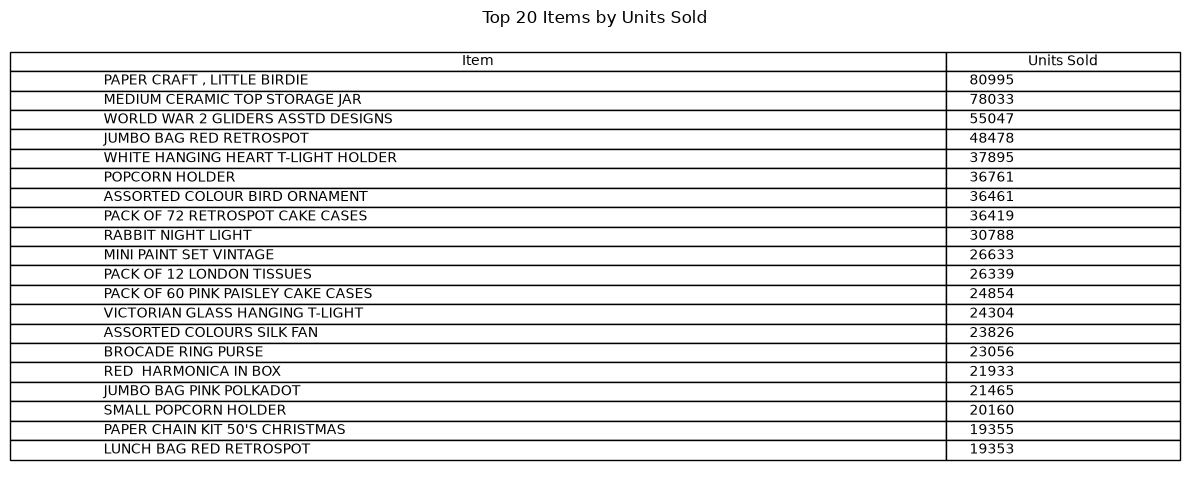

In [18]:
units_sold_by_item = sales_data_only.groupby("Description")["Quantity"].sum().sort_values(ascending=False)
units_table = (
    units_sold_by_item.head(20) # top 20 items
    .rename_axis("Item")
    .reset_index(name="Units Sold")
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.axis("off")
ax.set_title("Top 20 Items by Units Sold")

ax.table(
    cellText=units_table.values,
    colLabels=units_table.columns,
    cellLoc="left",
    loc="center",
    colWidths=[0.8, 0.2],
)

plt.tight_layout()
plt.show()

### What does a typical transaction look like?

In [ ]:

# average and median invoice value
sales_invoice_values = sales_data_only.groupby("InvoiceNumber")["LineItemPrice"].sum()
#print(invoice_values.array)
print(f"{sales_invoice_values.describe()}")

#log_values = np.log(invoice_values.array)
#print(f"Log-transformed Invoice Value: {pd.Series(log_values).describe()}")

#plt.figure(figsize=(12, 5))
#plt.hist(log_values, bins=50, edgecolor="black")
#plt.show()

#plt.boxplot(log_values, vert=False)
#plt.title("Invoice Value Distribution")
#plt.xlabel("Invoice Value")
#plt.show()

#median_invoice_value = sales_data_only.groupby("InvoiceNo")["LineItemPrice"].sum().median()
#print(f"Average Invoice Value: {invoice_values.mean()}")
#print(f"Median Invoice Value: {invoice_values.median()}")



count     18444.000000
mean        483.160264
std        1685.305136
min           0.000000
25%         159.182500
50%         303.385000
75%         474.165000
max      168469.600000
Name: LineItemPrice, dtype: float64


### Sales vs returns

In [23]:
return_data_only = retail_data[retail_data["Quantity"] < 0]
return_invoice_values = return_data_only.groupby("InvoiceNumber")["LineItemPrice"].sum()
print(f"{return_invoice_values.describe()}")
# print(f"{retail_invoice_values.describe()}")

count      3650.000000
mean       -167.490984
std        3181.349048
min     -168469.600000
25%         -37.495000
50%         -16.055000
75%          -7.650000
max          -0.390000
Name: LineItemPrice, dtype: float64
